In [1]:
import os
import zipfile
from google.colab import drive

print("--- MONTANDO O GOOGLE DRIVE ---")
drive.mount('/content/drive')

drive_folder = '/content/drive/MyDrive'

--- MONTANDO O GOOGLE DRIVE ---
Mounted at /content/drive


In [2]:
!pip install roboflow

from roboflow import Roboflow
from google.colab import userdata

# Dataset baixado direto da fonte original (Roboflow Universe, versão 2, formato YOLOv8)
rf = Roboflow(api_key=userdata.get('ROBOFLOW_KEY'))
project = rf.workspace("license-plates-acy8e").project("license-plates-xfeyr")
version = project.version(2)
dataset = version.download("yolov8", location="/content/dataset")

print("Conteúdo:", os.listdir('/content/dataset'))
print(open('/content/dataset/README.dataset.txt').read())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 103.7 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset in yolov8:: 100%|██████████| 42064/42064 [00:13<00:00, 3122.80it/s]


Conteúdo: ['data.yaml', 'test', 'README.roboflow.txt', 'valid', 'train', 'README.dataset.txt']
# License Plates > 2025-05-22 9:53pm
https://universe.roboflow.com/license-plates-acy8e/license-plates-xfeyr

Provided by a Roboflow user
License: CC BY 4.0




In [3]:
import os
from collections import Counter

def origem(nome):
    return os.path.splitext(nome)[0].split('.rf.')[0]

splits = {'train': 'train', 'val': 'valid', 'test': 'test'}
origens = {}
for s, pasta in splits.items():
    imgs = os.listdir(f'/content/dataset/{pasta}/images')
    origens[s] = {origem(f) for f in imgs}
    tipos = Counter()
    for f in os.listdir(f'/content/dataset/{pasta}/labels'):
        for linha in open(f'/content/dataset/{pasta}/labels/{f}'):
            n = len(linha.split())
            if n:
                tipos['caixa' if n == 5 else 'poligono'] += 1
    print(f"{s:5s}: {len(imgs)} imagens | {len(origens[s])} fotos de origem | rótulos: {dict(tipos)}")

print("\nFotos de origem compartilhadas:")
print("  val  ∩ train:", len(origens['val'] & origens['train']))
print("  test ∩ train:", len(origens['test'] & origens['train']))
print("  test ∩ val  :", len(origens['test'] & origens['val']))

train: 14984 imagens | 7492 fotos de origem | rótulos: {'caixa': 14984}
val  : 4012 imagens | 2006 fotos de origem | rótulos: {'caixa': 4608}
test : 2030 imagens | 1015 fotos de origem | rótulos: {'caixa': 2030}

Fotos de origem compartilhadas:
  val  ∩ train: 0
  test ∩ train: 0
  test ∩ val  : 0


In [3]:
import random
import numpy as np
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
print("Sementes fixadas para 42.")

Sementes fixadas para 42.


In [4]:
!nvidia-smi

Mon Nov 16 17:08:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q ultralytics==8.4.208

import os
import yaml
import time
import shutil
from ultralytics import YOLO

yaml_path = '/content/dataset/data.yaml'

# 1. Carregar e ajustar o caminho base no data.yaml
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

# Define a pasta raiz do dataset no Colab
data['path'] = '/content/dataset'

with open(yaml_path, 'w') as f:
    yaml.dump(data, f)

# 2. Verificação de vazamento adaptada para Roboflow (train vs valid)
def get_image_files(folder_path):
    if not os.path.exists(folder_path):
        return set()
    # Retorna arquivos se estiverem direto na pasta ou dentro da subpasta 'images'
    target_dir = os.path.join(folder_path, 'images') if os.path.exists(os.path.join(folder_path, 'images')) else folder_path
    return set(os.listdir(target_dir))

train_path = os.path.join(data['path'], 'train')
val_path = os.path.join(data['path'], 'valid')

train_imgs = get_image_files(train_path)
val_imgs = get_image_files(val_path)
overlap = train_imgs.intersection(val_imgs)

sementes = [42, 43, 44]
runs_baseline = []
tempos = []

print("--- VERIFICAÇÃO DO DATASET (ROBOFLOW) ---")
print(f"Total de imagens no Treino: {len(train_imgs)}")
print(f"Total de imagens na Validação: {len(val_imgs)}")

if len(overlap) > 0:
    print(f"ATENÇÃO: {len(overlap)} imagens possuem o mesmo nome no treino e na validação!")
else:
    print("Nenhuma imagem com nome idêntico foi compartilhada entre treino e validação.\n")

print("--- INICIANDO TREINAMENTO DO BASELINE (15 ÉPOCAS) ---")
for seed in sementes:
    print(f"\n---> TREINANDO SEMENTE {seed} <---")
    set_seed(seed)
    model_baseline = YOLO('yolov8n.yaml')

    start_time = time.time()

    # 4. Executar Treinamento
    results = model_baseline.train(
        data=yaml_path,
        epochs=15,
        imgsz=416,
        batch=16,
        seed=seed,
        device=0,
        project='/content/baseline_project',
        name=f'train_scratch_seed_{seed}',
        exist_ok=True,
        plots=True
    )

    end_time = time.time()
    exec_time = end_time - start_time
    tempos.append(exec_time / 60)
    run_dir = f'/content/baseline_project/train_scratch_seed_{seed}'
    runs_baseline.append(run_dir)
    #Faz uma cópia de segurança no meu DRIVE
    shutil.copytree(run_dir, f'/content/drive/MyDrive/T2_Grupo7_baseline/train_seed_{seed}', dirs_exist_ok=True)

    # 5. Métricas Finais
    print(f"Semente {seed} finalizada em {exec_time / 60:.2f} min")
print(f"\nTempo médio de treino: {np.mean(tempos):.2f} ± {np.std(tempos):.2f} minutos")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
--- VERIFICAÇÃO DO DATASET (ROBOFLOW) ---
Total de imagens no Treino: 14984
Total de imagens na Validação: 4012
Nenhuma imagem com nome idêntico foi compartilhada entre treino e validação.

--- INICIANDO TREINAMENTO DO BASELINE (15 ÉPOCAS) ---

---> TREINANDO SEMENTE 44 <---
New https://pypi.org/project/ultralytics/8.4.214 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=F

Semente 42: /content/drive/MyDrive/T2_Grupo7_baseline/train_seed_42/results.csv
Semente 43: /content/drive/MyDrive/T2_Grupo7_baseline/train_seed_43/results.csv
Semente 44: /content/drive/MyDrive/T2_Grupo7_baseline/train_seed_44/results.csv


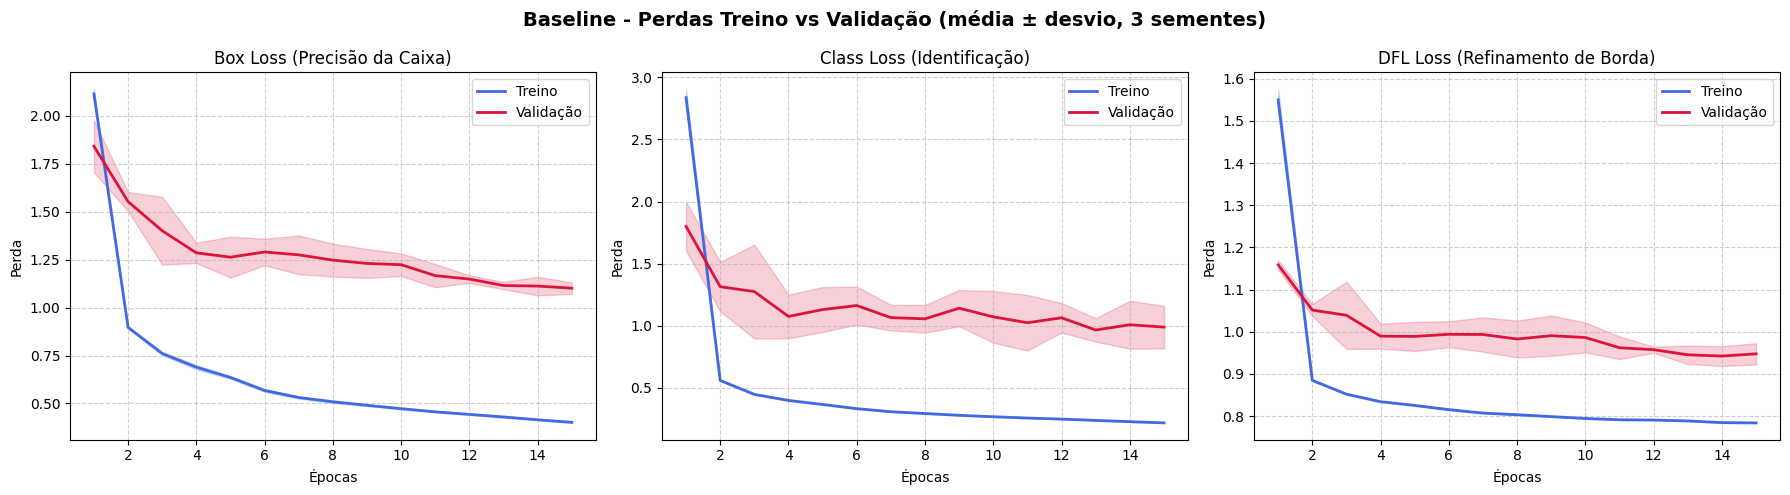


--- BASELINE: MELHOR ÉPOCA NA VALIDAÇÃO POR SEMENTE ---
 Semente  Melhor época  Precisão  Recall  mAP@0.5  mAP@0.5:0.95
      42            12    0.9512  0.6923   0.7502        0.6120
      43            15    0.9814  0.6870   0.7524        0.6200
      44            15    0.9544  0.7267   0.7837        0.6323

Média ± desvio:
  Precisão      : 0.9623 ± 0.0166
  Recall        : 0.7020 ± 0.0216
  mAP@0.5       : 0.7621 ± 0.0187
  mAP@0.5:0.95  : 0.6215 ± 0.0102


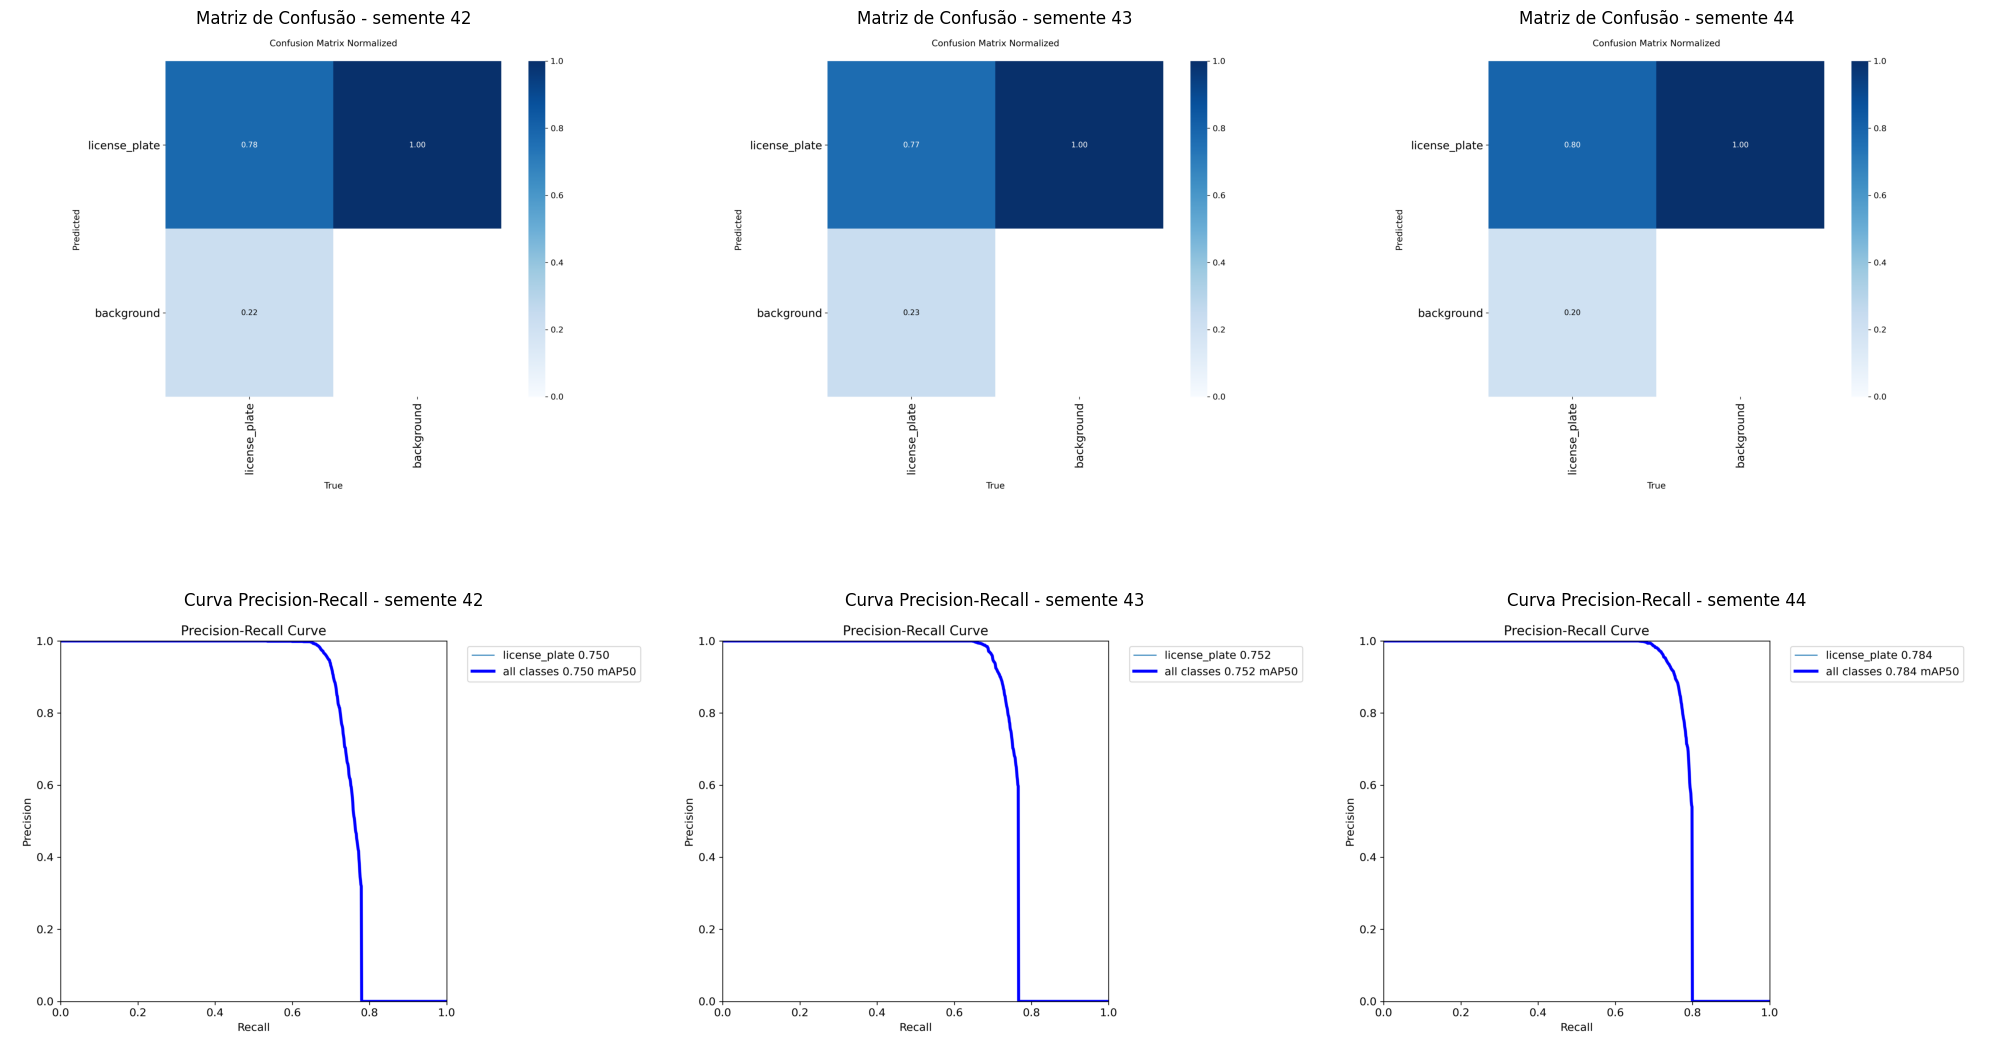

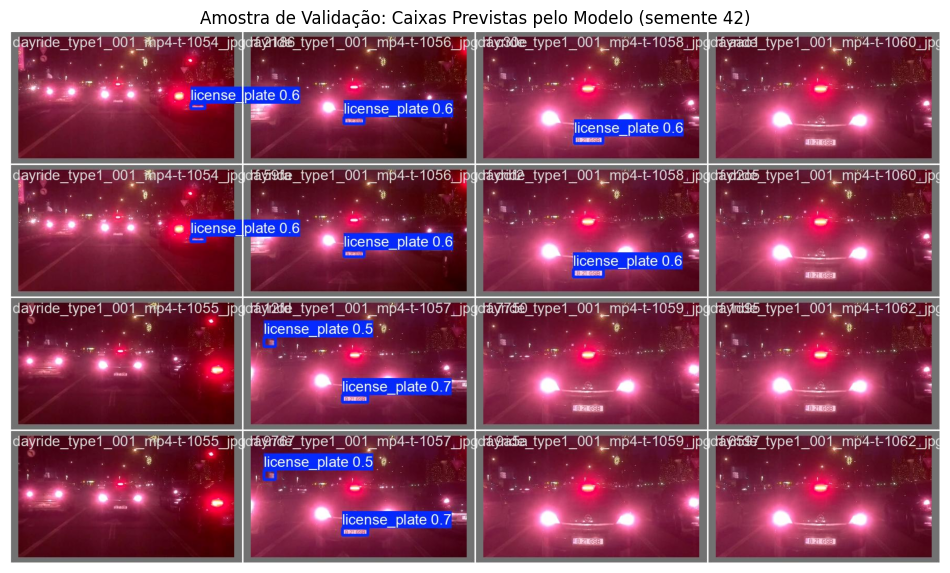

Diagnósticos concluídos e salvos em /content/painel_perdas_baseline.png


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

sementes = [42, 43, 44]
DRIVE_BASELINE = '/content/drive/MyDrive/T2_Grupo7_baseline'
runs_baseline = [f'{DRIVE_BASELINE}/train_seed_{seed}' for seed in sementes]

# --- 1. CARREGAR OS results.csv DAS 3 SEMENTES ---
dfs = []
for seed, run_dir in zip(sementes, runs_baseline):
    csv_path = os.path.join(run_dir, 'results.csv')
    print(f"Semente {seed}: {csv_path}")
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    df['seed'] = seed
    dfs.append(df)
df_all = pd.concat(dfs, ignore_index=True)

# Média e desvio por época entre as sementes
media = df_all.groupby('epoch').mean(numeric_only=True)
desvio = df_all.groupby('epoch').std(numeric_only=True)

# --- 2. PERDAS TREINO VS VALIDAÇÃO (MÉDIA ± DESVIO DAS 3 SEMENTES) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
perdas = [('box_loss', 'Box Loss (Precisão da Caixa)'),
          ('cls_loss', 'Class Loss (Identificação)'),
          ('dfl_loss', 'DFL Loss (Refinamento de Borda)')]

for ax, (perda, titulo) in zip(axes, perdas):
    for prefixo, rotulo, cor in [('train', 'Treino', 'royalblue'), ('val', 'Validação', 'crimson')]:
        col = f'{prefixo}/{perda}'
        ax.plot(media.index, media[col], label=rotulo, color=cor, linewidth=2)
        ax.fill_between(media.index, media[col] - desvio[col], media[col] + desvio[col], color=cor, alpha=0.2)
    ax.set_title(titulo)
    ax.set_xlabel('Épocas')
    ax.set_ylabel('Perda')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Baseline - Perdas Treino vs Validação (média ± desvio, 3 sementes)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/painel_perdas_baseline.png', dpi=300)
plt.show()

# --- 3. MÉTRICAS DE VALIDAÇÃO DA MELHOR ÉPOCA DE CADA SEMENTE ---
cols = {'metrics/precision(B)': 'Precisão', 'metrics/recall(B)': 'Recall',
        'metrics/mAP50(B)': 'mAP@0.5', 'metrics/mAP50-95(B)': 'mAP@0.5:0.95'}
linhas = []
for seed, df in zip(sementes, dfs):
    melhor = df.loc[df['metrics/mAP50-95(B)'].idxmax()]
    linhas.append({'Semente': seed, 'Melhor época': int(melhor['epoch']), **{v: melhor[k] for k, v in cols.items()}})
tabela = pd.DataFrame(linhas)
print("\n--- BASELINE: MELHOR ÉPOCA NA VALIDAÇÃO POR SEMENTE ---")
print(tabela.round(4).to_string(index=False))
print("\nMédia ± desvio:")
for m in cols.values():
    print(f"  {m:<14}: {tabela[m].mean():.4f} ± {tabela[m].std():.4f}")

# --- 4. MATRIZ DE CONFUSÃO E CURVA PR DE CADA SEMENTE ---
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for col, (seed, run_dir) in enumerate(zip(sementes, runs_baseline)):
    for linha, (arq, titulo) in enumerate([('confusion_matrix_normalized.png', 'Matriz de Confusão'),
                                           ('BoxPR_curve.png', 'Curva Precision-Recall')]):
        caminho = os.path.join(run_dir, arq)
        if os.path.exists(caminho):
            axes[linha, col].imshow(Image.open(caminho))
        else:
            axes[linha, col].text(0.5, 0.5, 'Arquivo não encontrado', ha='center', va='center')
        axes[linha, col].set_title(f'{titulo} - semente {seed}', fontsize=12)
        axes[linha, col].axis('off')
plt.tight_layout()
plt.show()

# --- 5. PREDIÇÕES NO CONJUNTO DE VALIDAÇÃO (SEMENTE 42) ---
val_pred_path = os.path.join(runs_baseline[0], 'val_batch0_pred.jpg')
if os.path.exists(val_pred_path):
    plt.figure(figsize=(12, 8))
    plt.imshow(Image.open(val_pred_path))
    plt.axis('off')
    plt.title('Amostra de Validação: Caixas Previstas pelo Modelo (semente 42)', fontsize=12)
    plt.show()

print("Diagnósticos concluídos e salvos em /content/painel_perdas_baseline.png")

In [ ]:
!pip install -q ultralytics==8.4.208

import time
import shutil
import numpy as np
import ultralytics
from ultralytics import YOLO

print("Versão do Ultralytics:", ultralytics.__version__)

yaml_path = '/content/dataset/data.yaml'
sementes = [42, 43, 44]

tempos = []
runs_ft = []

print("=== FINE-TUNING DO YOLOv8n (PESOS PRÉ-TREINADOS NO COCO) ===")

for seed in sementes:
    print(f"\n---> TREINANDO SEMENTE {seed} <---")
    set_seed(seed)

    # Pesos pré-treinados no COCO (o baseline usou 'yolov8n.yaml', pesos aleatórios)
    model_ft = YOLO('yolov8n.pt')

    start_time = time.time()

    # Mesmo orçamento do baseline: 15 épocas, imgsz 416, batch 16
    model_ft.train(
        data=yaml_path,
        epochs=15,
        imgsz=416,
        batch=16,
        seed=seed,
        device=0,
        project='/content/finetuning_project',
        name=f'train_seed_{seed}',
        exist_ok=True,
        plots=True
    )

    exec_time = (time.time() - start_time) / 60
    tempos.append(exec_time)
    run_dir = f'/content/finetuning_project/train_seed_{seed}'
    runs_ft.append(run_dir)

    #Faz uma cópia de segurança no meu DRIVE
    shutil.copytree(run_dir, f'/content/drive/MyDrive/T2_Grupo7_finetuning/train_seed_{seed}', dirs_exist_ok=True)

    print(f"Semente {seed} finalizada em {exec_time:.2f} min")

print(f"\nTempo médio de treino: {np.mean(tempos):.2f} ± {np.std(tempos):.2f} minutos")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Versão do Ultralytics: 8.4.208
=== FINE-TUNING DO YOLOv8n (PESOS PRÉ-TREINADOS NO COCO) ===

---> TREINANDO SEMENTE 42 <---
New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, devic

In [7]:
import pandas as pd
import numpy as np
import ultralytics
from ultralytics import YOLO
import os

sementes = [42, 43, 44]
DRIVE_BASELINE = '/content/drive/MyDrive/T2_Grupo7_baseline'
DRIVE_FT       = '/content/drive/MyDrive/T2_Grupo7_finetuning'

pesos_baseline = [f'{DRIVE_BASELINE}/train_seed_{seed}/weights/best.pt' for seed in sementes]
pesos_ft       = [f'{DRIVE_FT}/train_seed_{seed}/weights/best.pt' for seed in sementes]

for p in pesos_baseline + pesos_ft:
    print('OK ' if os.path.exists(p) else 'FALTANDO ', p)

yaml_path = '/content/dataset/data.yaml'

def avaliar(pesos, split, nome):
    m = YOLO(pesos).val(data=yaml_path, split=split, imgsz=416, batch=16, device=0,
                        project='/content/avaliacoes', name=f'{nome}_{split}', exist_ok=True, verbose=False)
    return {'modelo': nome, 'split': split,
            'Precisão': m.box.mp, 'Recall': m.box.mr,
            'mAP@0.5': m.box.map50, 'mAP@0.5:0.95': m.box.map,
            'Inferência (ms/img)': m.speed['inference']}

# Avalia baseline e fine-tuning com a mesma função, na validação e no teste
linhas = []
for split in ['val', 'test']:
    for seed, pesos in zip(sementes, pesos_baseline):
        linhas.append(avaliar(pesos, split, f'baseline_seed_{seed}'))
    for seed, pesos in zip(sementes, pesos_ft):
        linhas.append(avaliar(pesos, split, f'ft_seed_{seed}'))

df = pd.DataFrame(linhas)
print("=== MÉTRICAS POR MODELO ===")
print(df.round(4).to_string(index=False))

# Tabela resumo: baseline vs fine-tuning (média ± desvio das 3 sementes)
metricas = ['Precisão', 'Recall', 'mAP@0.5', 'mAP@0.5:0.95']
for split in ['val', 'test']:
    base = df[(df.split == split) & (df.modelo.str.startswith('baseline'))]
    ft = df[(df.split == split) & (df.modelo.str.startswith('ft'))]
    print(f"\n=== BASELINE vs FINE-TUNING ({'VALIDAÇÃO' if split == 'val' else 'TESTE'}) ===")
    print(f"{'Métrica':<15}{'Baseline':>20}{'Fine-tuning':>20}{'Ganho':>10}")
    for m in metricas:
        print(f"{m:<15}{base[m].mean():>11.4f} ± {base[m].std():.4f}{ft[m].mean():>11.4f} ± {ft[m].std():.4f}"
              f"{ft[m].mean() - base[m].mean():>+10.4f}")

# Tempo de treino lido do results.csv salvo no Drive (coluna 'time', em segundos acumulados)
def tempo_treino(pasta):
    d = pd.read_csv(os.path.join(pasta, 'results.csv')); d.columns = d.columns.str.strip()
    return d['time'].iloc[-1] / 60 if 'time' in d.columns else np.nan

t_base = [tempo_treino(f'{DRIVE_BASELINE}/train_seed_{s}') for s in sementes]
t_ft = [tempo_treino(f'{DRIVE_FT}/train_seed_{s}') for s in sementes]
print(f"\nTempo de treino -> Baseline: {np.mean(t_base):.2f} ± {np.std(t_base, ddof=1):.2f} min"
      f" | Fine-tuning: {np.mean(t_ft):.2f} ± {np.std(t_ft, ddof=1):.2f} min")

df.to_csv('/content/drive/MyDrive/T2_Grupo7_finetuning/metricas_baseline_vs_ft.csv', index=False)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
OK  /content/drive/MyDrive/T2_Grupo7_baseline/train_seed_42/weights/best.pt
OK  /content/drive/MyDrive/T2_Grupo7_baseline/train_seed_43/weights/best.pt
OK  /content/drive/MyDrive/T2_Grupo7_baseline/train_seed_44/weights/best.pt
OK  /content/drive/MyDrive/T2_Grupo7_finetuning/train_seed_42/weights/best.pt
OK  /content/drive/MyDrive/T2_Grupo7_finetuning/train_seed_43/weights/best.pt
OK  /content/drive/MyDrive/T2_Grupo7_finetuning/train_seed_44/weights/best.pt
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1995.8±779.1 MB/s, size: 93.7 

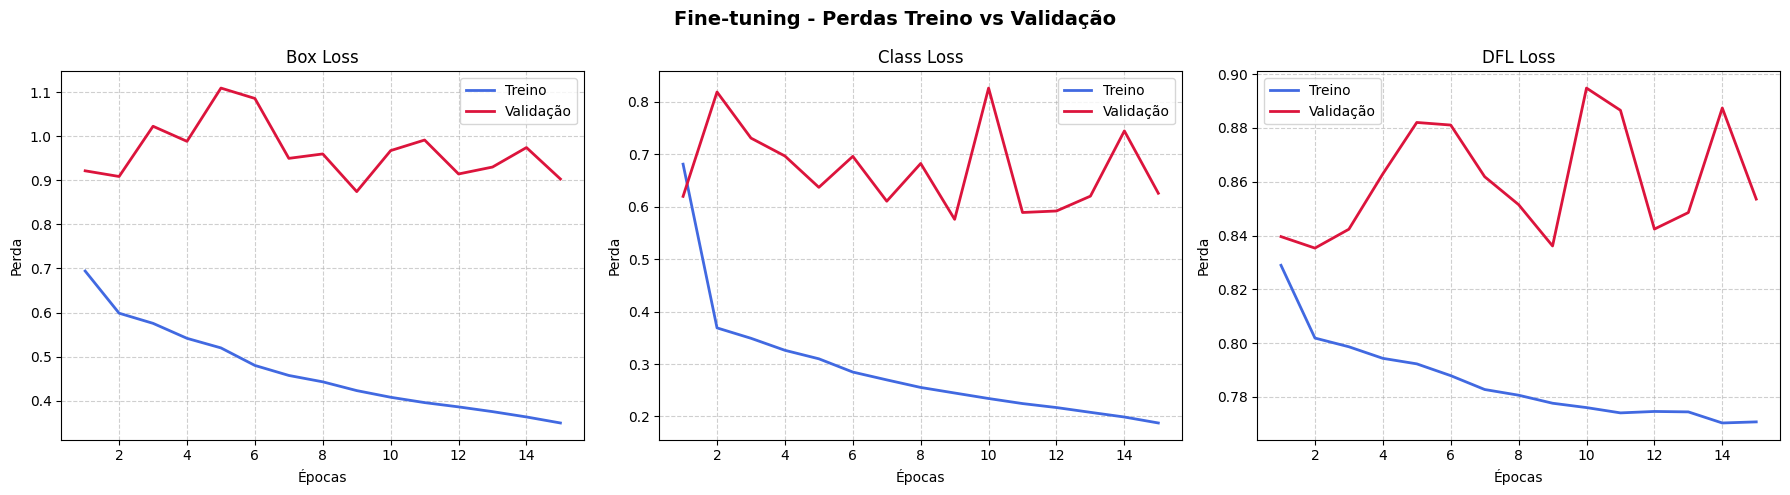

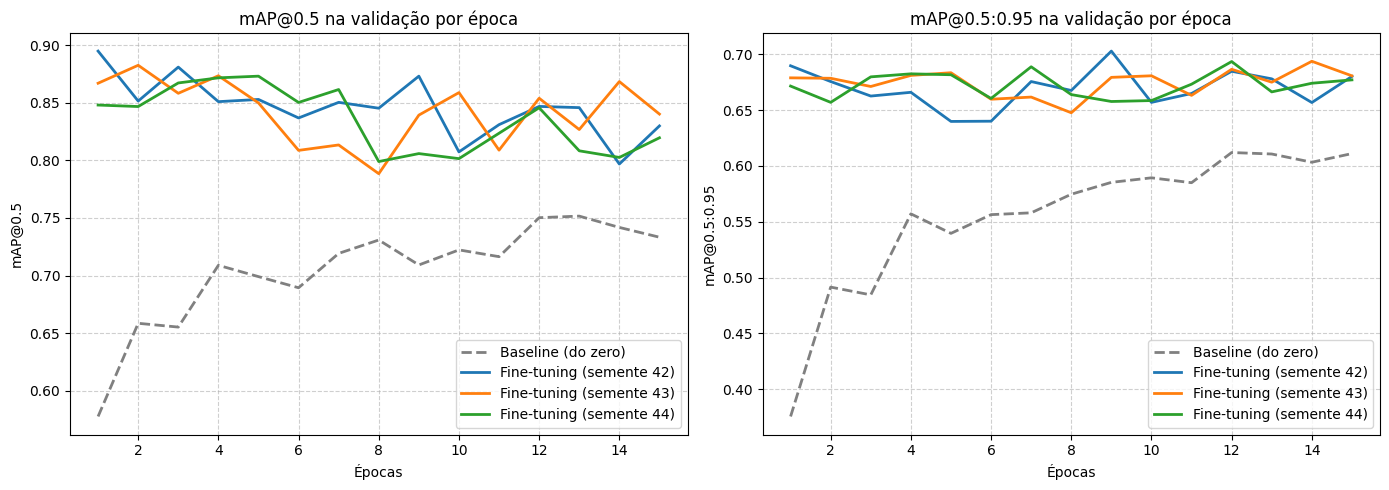

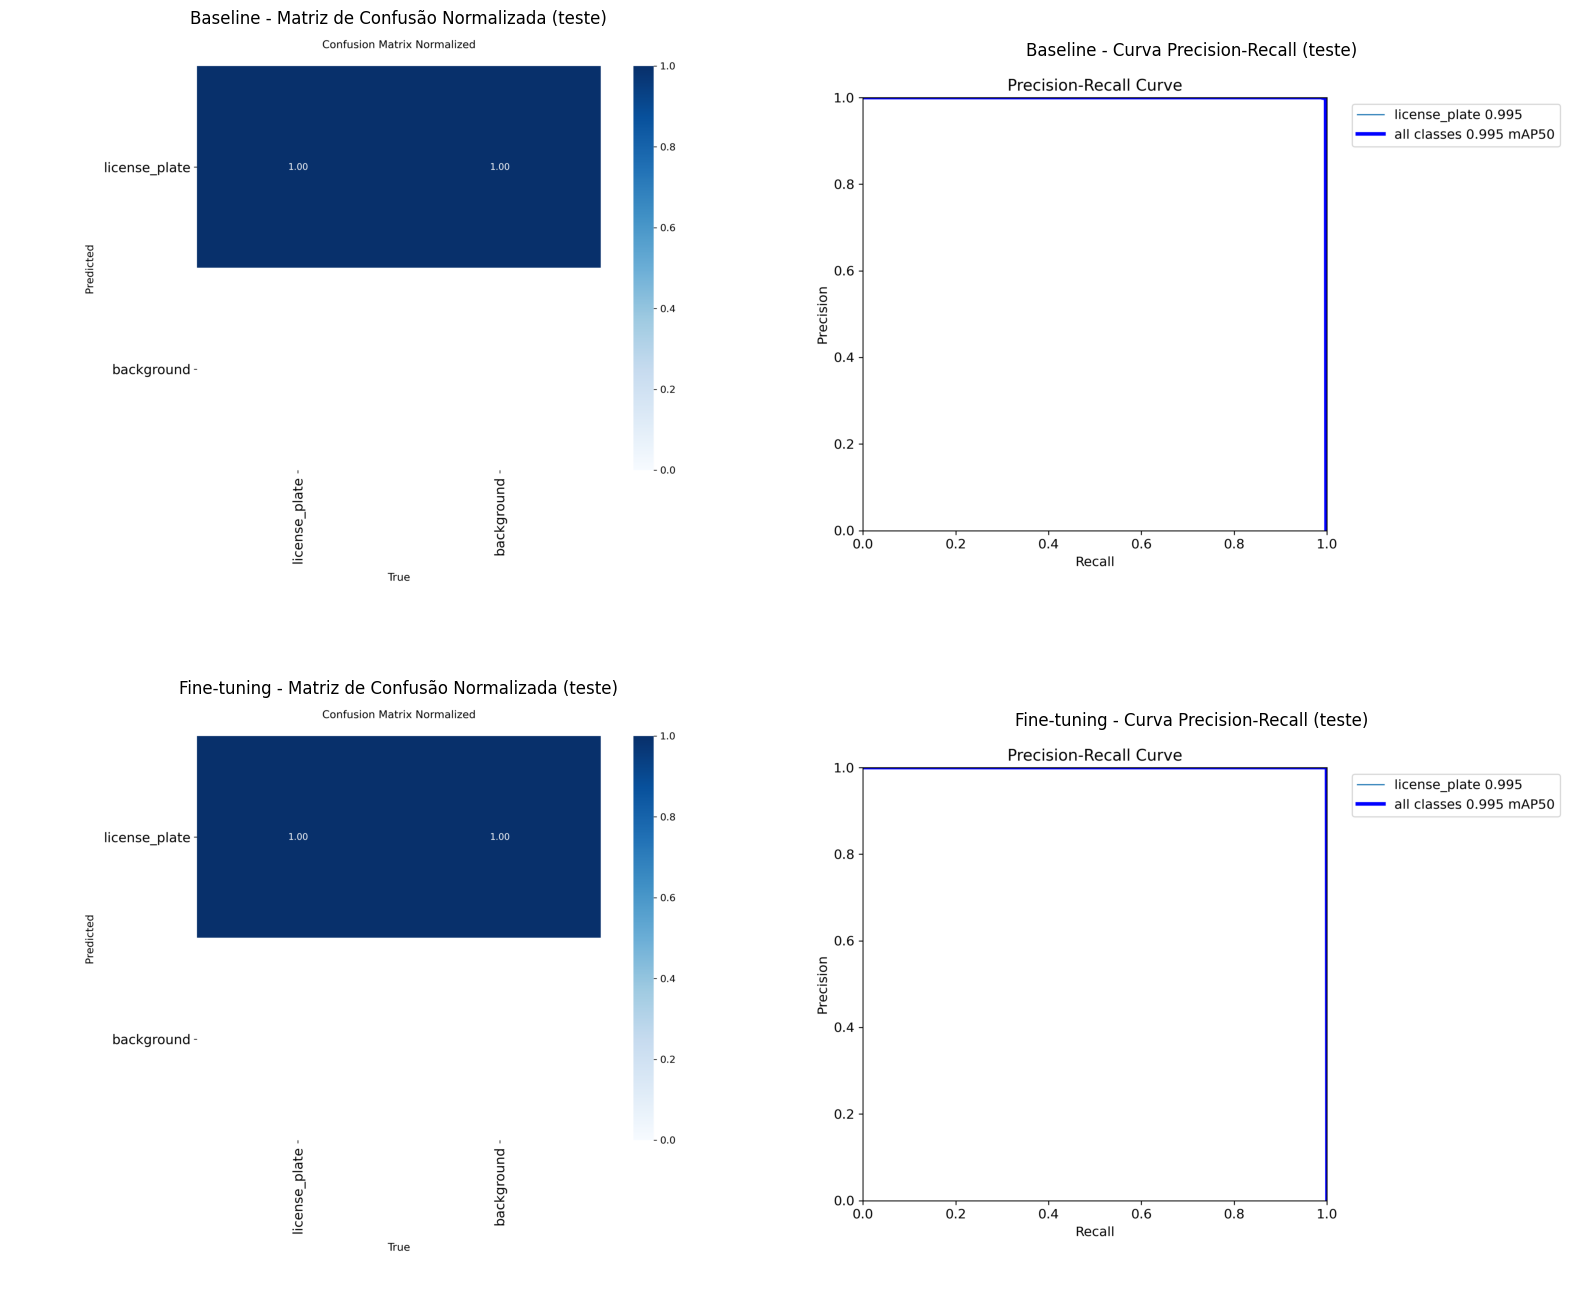

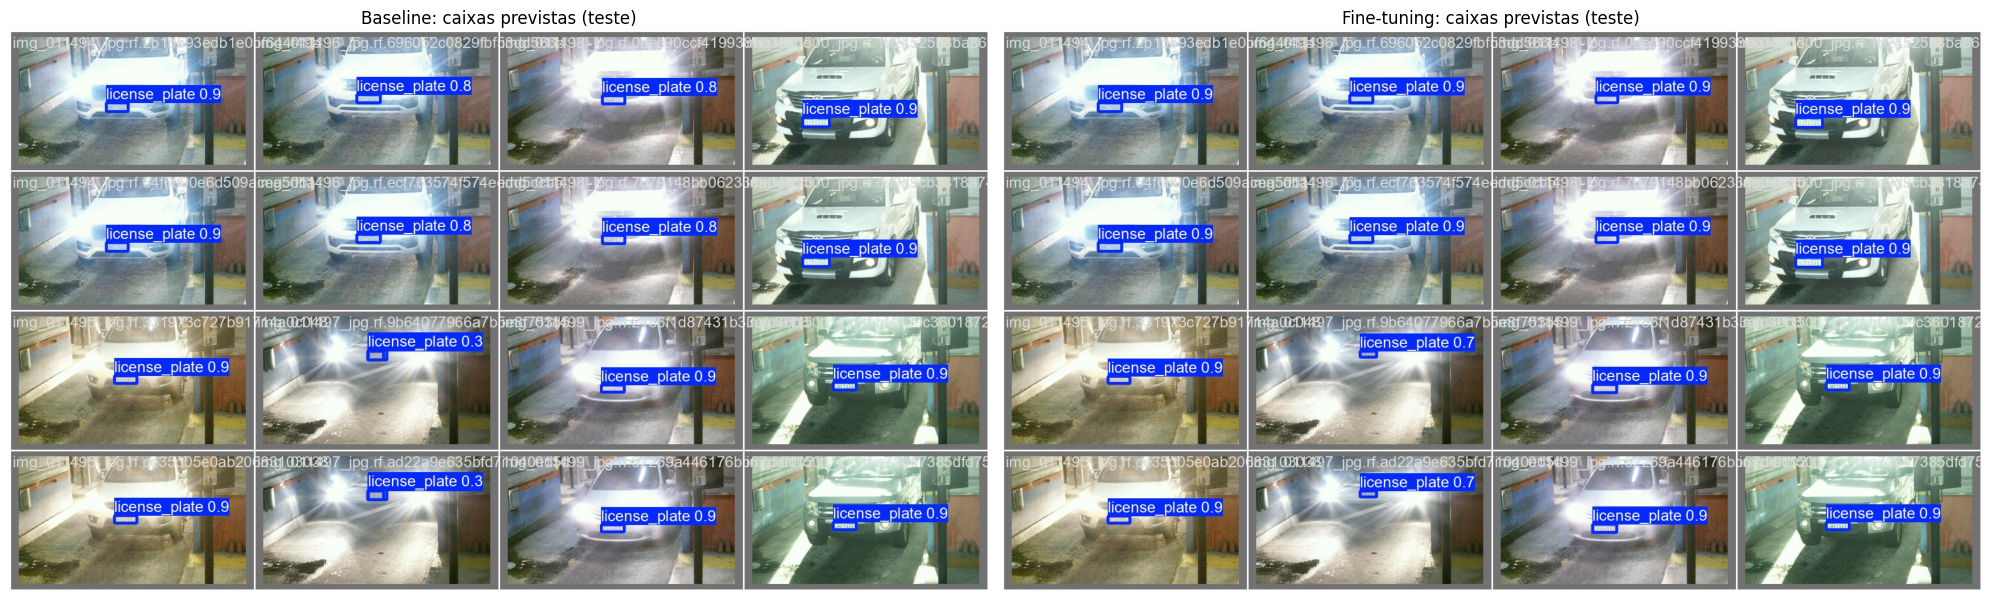

Gráficos salvos em /content/painel_perdas_finetuning.png e /content/convergencia_baseline_vs_ft.png


In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

sementes = [42, 43, 44]
runs_ft = [f'/content/drive/MyDrive/T2_Grupo7_finetuning/train_seed_{s}' for s in sementes]
run_ft = runs_ft[0]   # semente 42, para comparar com o baseline (também semente 42)
run_base = '/content/drive/MyDrive/T2_Grupo7_baseline/train_seed_42'

df_ft = pd.read_csv(os.path.join(run_ft, 'results.csv'));     df_ft.columns = df_ft.columns.str.strip()
df_base = pd.read_csv(os.path.join(run_base, 'results.csv')); df_base.columns = df_base.columns.str.strip()

# --- 1. PERDAS DE TREINO VS VALIDAÇÃO (FINE-TUNING) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, perda, titulo in zip(axes, ['box_loss', 'cls_loss', 'dfl_loss'],
                             ['Box Loss', 'Class Loss', 'DFL Loss']):
    ax.plot(df_ft['epoch'], df_ft[f'train/{perda}'], label='Treino', color='royalblue', linewidth=2)
    ax.plot(df_ft['epoch'], df_ft[f'val/{perda}'], label='Validação', color='crimson', linewidth=2)
    ax.set_title(titulo); ax.set_xlabel('Épocas'); ax.set_ylabel('Perda')
    ax.legend(); ax.grid(True, linestyle='--', alpha=0.6)
plt.suptitle('Fine-tuning - Perdas Treino vs Validação', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/painel_perdas_finetuning.png', dpi=300)
plt.show()

# --- 2. CONVERGÊNCIA: BASELINE VS FINE-TUNING ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, titulo in zip(axes, ['metrics/mAP50(B)', 'metrics/mAP50-95(B)'], ['mAP@0.5', 'mAP@0.5:0.95']):
    ax.plot(df_base['epoch'], df_base[col], label='Baseline (do zero)', color='gray', linestyle='--', linewidth=2)
    for run, seed in zip(runs_ft, sementes):
        d = pd.read_csv(os.path.join(run, 'results.csv')); d.columns = d.columns.str.strip()
        ax.plot(d['epoch'], d[col], label=f'Fine-tuning (semente {seed})', linewidth=2)
    ax.set_title(f'{titulo} na validação por época'); ax.set_xlabel('Épocas'); ax.set_ylabel(titulo)
    ax.legend(); ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('/content/convergencia_baseline_vs_ft.png', dpi=300)
plt.show()

# --- 3. MATRIZ DE CONFUSÃO E CURVA PR NO TESTE (BASELINE VS FINE-TUNING) ---
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for linha, (nome, pasta) in enumerate([('Baseline', '/content/avaliacoes/baseline_seed_42_test'),
                                       ('Fine-tuning', '/content/avaliacoes/ft_seed_42_test')]):
    for col, (arq, titulo) in enumerate([('confusion_matrix_normalized.png', 'Matriz de Confusão Normalizada'),
                                         ('BoxPR_curve.png', 'Curva Precision-Recall')]):
        caminho = os.path.join(pasta, arq)
        if os.path.exists(caminho):
            axes[linha, col].imshow(Image.open(caminho))
        else:
            axes[linha, col].text(0.5, 0.5, 'Arquivo não encontrado', ha='center', va='center')
        axes[linha, col].set_title(f'{nome} - {titulo} (teste)', fontsize=12)
        axes[linha, col].axis('off')
plt.tight_layout()
plt.show()

# --- 4. PREDIÇÕES NO TESTE: BASELINE VS FINE-TUNING ---
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, (nome, pasta) in zip(axes, [('Baseline', '/content/avaliacoes/baseline_seed_42_test'),
                                    ('Fine-tuning', '/content/avaliacoes/ft_seed_42_test')]):
    caminho = os.path.join(pasta, 'val_batch0_pred.jpg')
    if os.path.exists(caminho):
        ax.imshow(Image.open(caminho))
    ax.set_title(f'{nome}: caixas previstas (teste)', fontsize=12)
    ax.axis('off')
plt.tight_layout()
plt.show()


print("Gráficos salvos em /content/painel_perdas_finetuning.png e /content/convergencia_baseline_vs_ft.png")

In [9]:
import os, yaml
import pandas as pd
from ultralytics import YOLO

# Separa as imagens de validação por número de placas
lbl_dir = '/content/dataset/valid/labels'
img_dir = '/content/dataset/valid/images'
grupos = {'1_placa': [], '2+_placas': []}
for f in os.listdir(img_dir):
    lbl = os.path.join(lbl_dir, os.path.splitext(f)[0] + '.txt')
    n = sum(1 for l in open(lbl) if l.strip()) if os.path.exists(lbl) else 0
    grupos['1_placa' if n <= 1 else '2+_placas'].append(os.path.join(img_dir, f))

with open('/content/dataset/data.yaml') as fh:
    base_yaml = yaml.safe_load(fh)

for nome, imgs in grupos.items():
    lista = f'/content/dataset/val_{nome}.txt'
    with open(lista, 'w') as fh:
        fh.write('\n'.join(imgs))
    with open(f'/content/dataset/data_{nome}.yaml', 'w') as fh:
        yaml.dump({**base_yaml, 'val': lista}, fh)
    print(f"{nome}: {len(imgs)} imagens")

# Avalia os 6 modelos em cada subconjunto
linhas = []
for nome in grupos:
    for tipo, pesos_lista in [('baseline', pesos_baseline), ('ft', pesos_ft)]:
        for seed, pesos in zip(sementes, pesos_lista):
            m = YOLO(pesos).val(data=f'/content/dataset/data_{nome}.yaml', split='val', imgsz=416, batch=16,
                                device=0, project='/content/avaliacoes', name=f'{tipo}_{seed}_{nome}',
                                exist_ok=True, verbose=False, plots=False)
            linhas.append({'subconjunto': nome, 'modelo': tipo, 'seed': seed,
                           'Recall': m.box.mr, 'mAP@0.5': m.box.map50, 'mAP@0.5:0.95': m.box.map})

df_sub = pd.DataFrame(linhas)
resumo = df_sub.groupby(['subconjunto', 'modelo'])[['Recall', 'mAP@0.5', 'mAP@0.5:0.95']].agg(['mean', 'std'])
print(resumo.round(4).to_string())
df_sub.to_csv('/content/drive/MyDrive/T2_Grupo7_finetuning/val_por_numero_de_placas.csv', index=False)

1_placa: 3522 imagens
2+_placas: 490 imagens
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2192.3±927.4 MB/s, size: 104.7 KB)
val: Scanning /content/dataset/valid/labels... 3522 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3522/3522 953.5it/s 3.7s
val: New cache created: /content/dataset/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 221/221 8.0it/s 27.6s
                   all       3522       3522       0.99      0.861      0.905      0.766
Speed: 0.5ms preprocess, 1.7ms inference, 0.0ms loss, 2.2ms postprocess per image
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read